# Migration des segments RFM : 2014-15 → 2015-16 (bonus)

On recalcule la segmentation RFM sur l'année précédente et on la croise avec celle de la période d'étude, pour voir comment les clientes changent de segment.

- **Période N-1** : 01/09/2014 → 31/08/2015 (récence et ancienneté calculées au 31/08/2015)
- **Période N** : 01/09/2015 → 31/08/2016 (segmentation du notebook principal)

Les deux périodes sont **disjointes**, de même durée (12 mois complets) et alignées sur la même saison, donc comparables. On garde **les mêmes seuils** (140/280 €, 1/2/3+ visites, 60/150 jours) : sinon un changement de segment pourrait venir d'un changement de seuil et non de comportement.

Statuts hors segments :
- **Inactive** : cliente déjà titulaire de la carte à la fin de la période, mais sans achat (ou avec un CA nul) sur la période.
- **Pas encore cliente** : carte créée après la fin de la période N-1.

In [1]:
%%capture
%run Notebook_project1_completed.ipynb

In [2]:
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

os.makedirs('figures', exist_ok = True)

DECEL = '#eb6834'
COMP = '#2a78d6'
OTHER = '#bdbbb4'
INK = '#0b0b0b'
INK2 = '#52514e'

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#d6d4cd', 'axes.labelcolor': INK2,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#ecebe6', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})

def save(fig, name):
    fig.savefig(f'figures/{name}.png', dpi = 200, bbox_inches = 'tight')

## 1. Une fonction de segmentation réutilisable

Elle reprend exactement les étapes du notebook principal (clé de visite à 4 colonnes, exclusion des CA nuls, New = ancienneté < 1 an, grille FM du cours slide 24, consolidation slide 26).

In [3]:
CARD = CUSTOMERS_INFO_OK.set_index('ID_INDIVIDU')['DATE_CREATION_CARTE']

def build_rfm(start, end):
    rec = RECEIPTS_INFO_OK[(RECEIPTS_INFO_OK['DATE_ACHAT'] >= start) & (RECEIPTS_INFO_OK['DATE_ACHAT'] <= end)]
    visits = (
        rec.groupby(['ID_INDIVIDU', 'CODE_BOUTIQUE', 'DATE_ACHAT', 'NUM_TICKET'])
        .agg(NB_PRODUCTS = ('QUANTITE', 'sum'), MONETARY_VALUE = ('PRICE', 'sum'))
        .reset_index()
    )
    ind = (
        visits.groupby('ID_INDIVIDU')
        .agg(NB_VISITS = ('DATE_ACHAT', 'count'), CUMUL_VALUE = ('MONETARY_VALUE', 'sum'), LAST_PURCHASE = ('DATE_ACHAT', 'max'))
        .reset_index()
    )
    ind['RECENCY'] = (end - ind['LAST_PURCHASE']).dt.days
    ind = ind[ind['CUMUL_VALUE'] > 0].copy()

    seniority = (end - ind['ID_INDIVIDU'].map(CARD)).dt.days / 365
    seniority = seniority.where(seniority <= 10).clip(lower = 0)
    new = seniority < 1

    R = np.select([new, ind['RECENCY'] > max_recency, ind['RECENCY'] <= min_recency], ['New', 'Low', 'High'], 'Medium')
    F = np.select([new, ind['NB_VISITS'] <= min_frequency, ind['NB_VISITS'] >= max_frequency], ['New', 'Low', 'High'], 'Medium')
    M = np.select([new, ind['CUMUL_VALUE'] < min_money, ind['CUMUL_VALUE'] > max_money], ['New', 'Low', 'High'], 'Medium')
    FM = pd.Series(list(zip(F, M)), index = ind.index)
    low_fm = FM.isin([('Low', 'Low'), ('Low', 'Medium'), ('Medium', 'Low')])
    fm_med_high = ~low_fm & ~new

    ind['RFM_SEG'] = np.select(
        [new, fm_med_high & (R == 'High'), fm_med_high & (R == 'Medium'), fm_med_high & (R == 'Low'),
         low_fm & np.isin(R, ['High', 'Medium']), low_fm & (R == 'Low')],
        ['New', '5 Top', '4 Good', '3 Decel', '2 Small', '1 Weak'],
        default = 'NON CLASSÉ',
    )
    assert (ind['RFM_SEG'] != 'NON CLASSÉ').all()
    return ind

In [4]:
SEG_N = build_rfm(pd.Timestamp('2015-09-01'), pd.Timestamp('2016-08-31'))
check = pd.DataFrame({
    'build_rfm (N)': SEG_N['RFM_SEG'].value_counts(),
    'notebook principal': MASTER_RFM['RFM_SEG'].value_counts(),
})
check['identique'] = check.iloc[:, 0] == check.iloc[:, 1]
check

,build_rfm (N),notebook principal,identique
RFM_SEG,,,
New,4694,4694,True
5 Top,1964,1964,True
1 Weak,1782,1782,True
4 Good,1584,1584,True
2 Small,1510,1510,True
3 Decel,806,806,True


In [5]:
# Contrôle client par client
cmp = SEG_N[['ID_INDIVIDU', 'RFM_SEG']].merge(MASTER_RFM[['ID_INDIVIDU', 'RFM_SEG']], on = 'ID_INDIVIDU', suffixes = ('_fn', '_nb'))
print('Clients comparés :', len(cmp), '| segments différents :', (cmp['RFM_SEG_fn'] != cmp['RFM_SEG_nb']).sum())

Clients comparés : 12340 | segments différents : 0


## 2. Segmentation de l'année précédente (N-1)

In [6]:
START_N1, END_N1 = pd.Timestamp('2014-09-01'), pd.Timestamp('2015-08-31')
SEG_N1 = build_rfm(START_N1, END_N1)

SEG_ORDER = ['5 Top', '4 Good', '3 Decel', '2 Small', '1 Weak', 'New']
COMPARE = pd.DataFrame({
    'Clients N-1 (2014-15)': SEG_N1['RFM_SEG'].value_counts(),
    'Clients N (2015-16)': SEG_N['RFM_SEG'].value_counts(),
    'CA N-1 (€)': SEG_N1.groupby('RFM_SEG')['CUMUL_VALUE'].sum(),
    'CA N (€)': SEG_N.groupby('RFM_SEG')['CUMUL_VALUE'].sum(),
}).reindex(SEG_ORDER)
COMPARE.loc['Total actifs'] = COMPARE.sum()
COMPARE['Évolution clients (%)'] = 100 * (COMPARE['Clients N (2015-16)'] / COMPARE['Clients N-1 (2014-15)'] - 1)
COMPARE.round(1)

,Clients N-1 (2014-15),Clients N (2015-16),CA N-1 (€),CA N (€),Évolution clients (%)
RFM_SEG,,,,,
5 Top,1394,1964,594200,927949,40.9
4 Good,1445,1584,507456,593206,9.6
3 Decel,588,806,157127,228125,37.1
2 Small,1211,1510,119383,161725,24.7
1 Weak,1571,1782,149581,177974,13.4
New,4186,4694,986667,1185916,12.1
Total actifs,10395,12340,2514414,3274895,18.7


In [7]:
# Les seuils fixes restent-ils pertinents en N-1 ? Quantiles 33 % / 67 % des deux périodes (hors New)
q = pd.DataFrame({
    'N-1': SEG_N1.loc[SEG_N1['RFM_SEG'] != 'New', ['CUMUL_VALUE', 'NB_VISITS', 'RECENCY']].quantile([0.33, 0.67]).stack(),
    'N': SEG_N.loc[SEG_N['RFM_SEG'] != 'New', ['CUMUL_VALUE', 'NB_VISITS', 'RECENCY']].quantile([0.33, 0.67]).stack(),
})
q

N-1      N
0.33 CUMUL_VALUE  117.00  130.0
     NB_VISITS      1.00    1.0
     RECENCY       63.00   60.0
0.67 CUMUL_VALUE  256.00  282.0
     NB_VISITS      3.00    3.0
     RECENCY      157.72  154.0

**Lecture :** la base active passe de 10 395 à 12 340 clientes (+19 %). La hausse des Top (+41 %) s'explique par deux effets mécaniques, à garder en tête dans l'interprétation :
- un **effet de cohorte** : la grosse cohorte New 2014-15 sort du statut New en N, donc les clientes « non New » passent de 6 209 à 7 646 (+23 %) ;
- un **effet de seuil** : la dépense par cliente augmente (quantile 67 % du CA : 256 € → 282 €) alors que les seuils restent fixes.

## 3. Matrice de migration N-1 → N

In [8]:
ALL_IDS = CUSTOMERS_INFO_OK['ID_INDIVIDU']
card = ALL_IDS.map(CARD)

state_n1 = pd.Series('Inactive', index = ALL_IDS.values)
state_n1[card.values > END_N1] = 'Pas encore cliente'
state_n1[SEG_N1['ID_INDIVIDU'].values] = SEG_N1['RFM_SEG'].values

state_n = pd.Series('Inactive', index = ALL_IDS.values)
state_n[card.values > max_date_RFM] = 'Pas encore cliente'
state_n[SEG_N['ID_INDIVIDU'].values] = SEG_N['RFM_SEG'].values

MIG = pd.DataFrame({'N-1': state_n1, 'N': state_n})
# On ne garde que les clientes actives au moins une des deux années
MIG = MIG[(MIG['N-1'].isin(SEG_ORDER)) | (MIG['N'].isin(SEG_ORDER))]

ROWS = SEG_ORDER + ['Inactive', 'Pas encore cliente']
COLS = SEG_ORDER + ['Inactive']
MATRIX = pd.crosstab(MIG['N-1'], MIG['N']).reindex(index = ROWS, columns = COLS).fillna(0).astype(int)
MATRIX.loc['Total'] = MATRIX.sum()
MATRIX['Total'] = MATRIX.sum(axis = 1)
MATRIX

N,5 Top,4 Good,3 Decel,2 Small,1 Weak,New,Inactive,Total
N-1,,,,,,,,
5 Top,518,275,100,143,138,0,220,1394
4 Good,406,309,104,148,181,0,297,1445
3 Decel,98,88,64,77,81,0,180,588
2 Small,120,123,61,166,179,0,562,1211
1 Weak,105,124,73,169,216,0,884,1571
New,541,488,279,378,511,3,1986,4186
Inactive,174,175,122,429,470,0,0,1370
Pas encore cliente,2,2,3,0,6,4691,0,4704
Total,1964,1584,806,1510,1782,4694,4129,16469


In [9]:
# Lecture en ligne : que sont devenues les clientes de chaque segment N-1 ? (en %)
ROW_PCT = pd.crosstab(MIG['N-1'], MIG['N'], normalize = 'index').reindex(index = ROWS, columns = COLS).fillna(0) * 100
ROW_PCT.round(1)

N,5 Top,4 Good,3 Decel,2 Small,1 Weak,New,Inactive
N-1,,,,,,,
5 Top,37.2,19.7,7.2,10.3,9.9,0.0,15.8
4 Good,28.1,21.4,7.2,10.2,12.5,0.0,20.6
3 Decel,16.7,15.0,10.9,13.1,13.8,0.0,30.6
2 Small,9.9,10.2,5.0,13.7,14.8,0.0,46.4
1 Weak,6.7,7.9,4.6,10.8,13.7,0.0,56.3
New,12.9,11.7,6.7,9.0,12.2,0.1,47.4
Inactive,12.7,12.8,8.9,31.3,34.3,0.0,0.0
Pas encore cliente,0.0,0.0,0.1,0.0,0.1,99.7,0.0


In [10]:
# Cas limites : clientes « pas encore clientes » en N-1 mais non New en N
edge = MIG[(MIG['N-1'] == 'Pas encore cliente') & (MIG['N'] != 'New')].index
print(len(edge), 'cas limites')
print(CARD.loc[edge].value_counts().sort_index())

13 cas limites
DATE_CREATION_CARTE
2015-09-01    13
Name: count, dtype: int64


*Les 13 cas limites ont une carte créée le 01/09/2015, premier jour de la période N : leur ancienneté au 31/08/2016 vaut exactement 365 jours = 1 an, donc ils ne sont pas New (règle « ancienneté < 1 an » du notebook, qui redonne les 4 694 New de référence). Effet négligeable.*

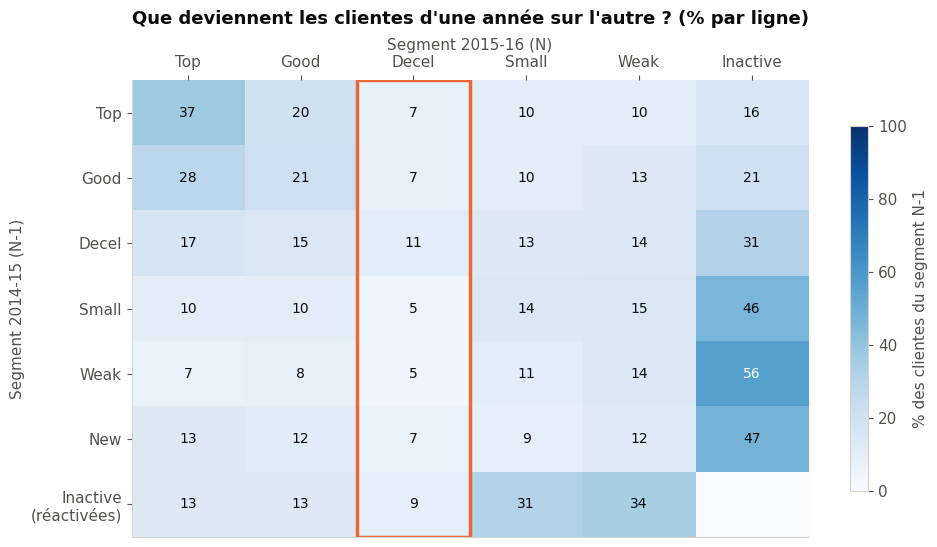

In [11]:
LABEL = {'5 Top': 'Top', '4 Good': 'Good', '3 Decel': 'Decel', '2 Small': 'Small', '1 Weak': 'Weak', 'New': 'New',
         'Inactive': 'Inactive', 'Pas encore cliente': 'Pas encore\ncliente'}
ROW_LABEL = dict(LABEL, Inactive = 'Inactive\n(réactivées)')
HM = ROW_PCT.drop(index = 'Pas encore cliente', columns = 'New')
fig, ax = plt.subplots(figsize = (10, 5.6))
im = ax.imshow(HM.values, cmap = 'Blues', vmin = 0, vmax = 100, aspect = 'auto')
ax.grid(False)
for i in range(HM.shape[0]):
    for j in range(HM.shape[1]):
        v = HM.values[i, j]
        if v >= 0.5:
            ax.text(j, i, f'{v:.0f}', ha = 'center', va = 'center', fontsize = 10, color = 'white' if v > 50 else INK)
ax.set_xticks(range(HM.shape[1]), [LABEL[c] for c in HM.columns])
ax.set_yticks(range(HM.shape[0]), [ROW_LABEL[r] for r in HM.index])
ax.set_xlabel('Segment 2015-16 (N)')
ax.set_ylabel('Segment 2014-15 (N-1)')
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
col = list(HM.columns).index('3 Decel')
ax.add_patch(plt.Rectangle((col - 0.5, -0.5), 1, HM.shape[0], fill = False, edgecolor = DECEL, lw = 2.5))
cb = fig.colorbar(im, ax = ax, shrink = 0.8)
cb.set_label('% des clientes du segment N-1', color = INK2)
ax.set_title('Que deviennent les clientes d\'une année sur l\'autre ? (% par ligne)', pad = 40)
fig.tight_layout()
save(fig, '08_matrice_migration')

**Lecture de la matrice :**
- La base est **très mobile** : seules 37 % des Top 2014-15 restent Top, et 16 % deviennent même inactives.
- **Les New sont le maillon faible** : 47 % des New 2014-15 n'ont rien acheté l'année suivante.
- Les Top et les Good « tombent » en Decel dans les mêmes proportions (7 %).
- La ligne « Inactive » ne contient, par construction, que les 1 370 clientes inactives en N-1 **qui ont racheté** en N (d'où la case Inactive → Inactive vide).

## 4. Focus Decel : d'où viennent les Decel 2016 ?

In [12]:
ORIG = MIG[MIG['N'] == '3 Decel']['N-1'].value_counts().reindex(ROWS).fillna(0).astype(int)
ORIG_PCT = 100 * ORIG / ORIG.sum()

# Référence : origine de toutes les clientes actives non New en N
ref = MIG[MIG['N'].isin(['5 Top', '4 Good', '3 Decel', '2 Small', '1 Weak'])]['N-1'].value_counts().reindex(ROWS).fillna(0)
REF_PCT = 100 * ref / ref.sum()
ORIGIN = pd.DataFrame({
    'Decel 2016': ORIG,
    'Decel 2016 (%)': ORIG_PCT.round(1),
    'Actives non New 2016 (%)': REF_PCT.round(1),
    'Indice (réf. = 100)': (100 * ORIG_PCT / REF_PCT).round(0),
})
ORIGIN

,Decel 2016,Decel 2016 (%),Actives non New 2016 (%),Indice (réf. = 100)
N-1,,,,
5 Top,100,12.4,15.4,81.0
4 Good,104,12.9,15.0,86.0
3 Decel,64,7.9,5.3,149.0
2 Small,61,7.6,8.5,89.0
1 Weak,73,9.1,9.0,101.0
New,279,34.6,28.7,120.0
Inactive,122,15.1,17.9,84.0
Pas encore cliente,3,0.4,0.2,219.0


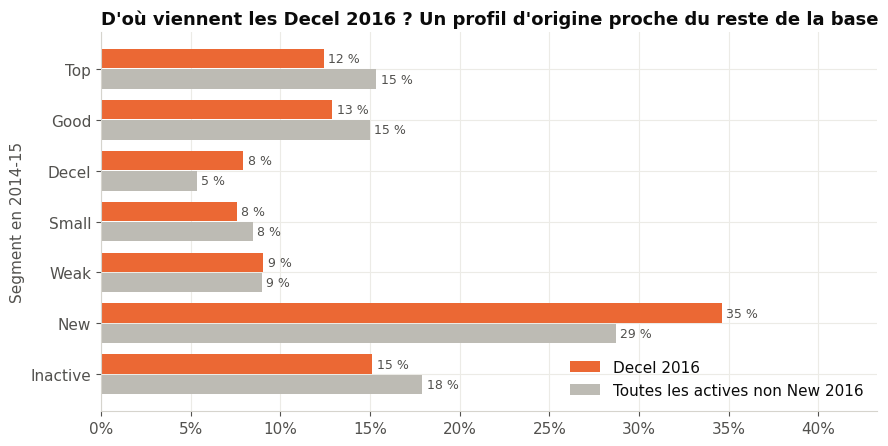

In [13]:
rows = [r for r in ROWS if r != 'Pas encore cliente']
labels = [LABEL[r] for r in rows]
y = np.arange(len(rows))
fig, ax = plt.subplots(figsize = (9, 4.6))
b1 = ax.barh(y - 0.2, ORIG_PCT[rows].values, height = 0.38, color = DECEL, label = 'Decel 2016')
b2 = ax.barh(y + 0.2, REF_PCT[rows].values, height = 0.38, color = OTHER, label = 'Toutes les actives non New 2016')
ax.bar_label(b1, fmt = '%.0f %%', padding = 3, color = INK2, fontsize = 9)
ax.bar_label(b2, fmt = '%.0f %%', padding = 3, color = INK2, fontsize = 9)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_xlim(0, max(ORIG_PCT.max(), REF_PCT.max()) * 1.25)
ax.set_ylabel('Segment en 2014-15')
ax.legend(loc = 'lower right')
ax.set_title("D'où viennent les Decel 2016 ? Un profil d'origine proche du reste de la base")
fig.tight_layout()
save(fig, '09_origine_decel')

**Lecture :** les Decel 2016 viennent de tous les segments, avec une répartition proche de celle de l'ensemble des actives non New.
- **35 % sont des clientes en 2e année de carte** (New en 2014-15), contre 29 % dans la base de référence : un **léger sur-poids** (indice ≈ 120). Ce chiffre reflète surtout le poids de la grosse cohorte 2014-15. Ces clientes avaient une première année un peu au-dessus de la moyenne des New (291 € et 2,6 visites, contre 236 € et 2,0).
- **25 % sont d'anciennes Top ou Good**, contre 30 % dans la base : **sous-représentées**. Le segment n'est donc pas principalement fait d'anciennes meilleures clientes qui décrochent.
- **15 % étaient inactives en 2014-15** (18 % dans la base).

Conséquence opérationnelle : l'origine N-1 peut servir à **adapter le message** à l'intérieur des Decel (2e année, ancienne Top/Good, réactivée), mais elle ne définit pas un profil type.

*Cas marginaux : 3 clientes actives en N-1 ont une carte créée après le 31/08/2015 (achats antérieurs à la création de la carte), classées New via la règle « ancienneté négative ramenée à 0 ». Effet négligeable.*

## 5. Focus Decel : que deviennent les Decel d'une année sur l'autre ?

Les Decel 2014-15 permettent de voir si le segment est **récupérable** : combien sont revenues en Top/Good l'année suivante, sans action marketing ciblée ?

In [14]:
FATE = ROW_PCT.loc['3 Decel']
n_decel_n1 = (MIG['N-1'] == '3 Decel').sum()
print(f'Decel 2014-15 : {n_decel_n1} clientes')
print(f"  → Top ou Good en 2015-16 : {FATE[['5 Top', '4 Good']].sum():.1f} %")
print(f"  → Toujours Decel : {FATE['3 Decel']:.1f} %")
print(f"  → Small ou Weak : {FATE[['2 Small', '1 Weak']].sum():.1f} %")
print(f"  → Inactives : {FATE['Inactive']:.1f} %")
FATE.round(1)

Decel 2014-15 : 588 clientes
  → Top ou Good en 2015-16 : 31.6 %
  → Toujours Decel : 10.9 %
  → Small ou Weak : 26.9 %
  → Inactives : 30.6 %


N
5 Top       16.7
4 Good      15.0
3 Decel     10.9
2 Small     13.1
1 Weak      13.8
New          0.0
Inactive    30.6
Name: 3 Decel, dtype: float64

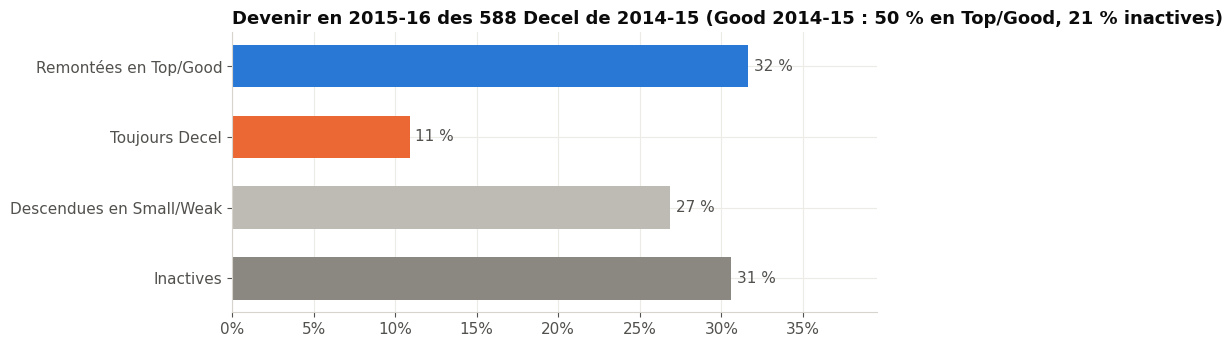

In [15]:
fig, ax = plt.subplots(figsize = (9, 3.6))
groups = {
    'Remontées en Top/Good': FATE[['5 Top', '4 Good']].sum(),
    'Toujours Decel': FATE['3 Decel'],
    'Descendues en Small/Weak': FATE[['2 Small', '1 Weak']].sum(),
    'Inactives': FATE['Inactive'],
}
gcolors = [COMP, DECEL, OTHER, '#8a8880']
bars = ax.barh(list(groups.keys()), list(groups.values()), color = gcolors, height = 0.6)
ax.bar_label(bars, fmt = '%.0f %%', padding = 4, color = INK2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
ax.set_xlim(0, max(groups.values()) * 1.25)
ax.set_title(f"Devenir en 2015-16 des {n_decel_n1} Decel de 2014-15 (Good 2014-15 : 50 % en Top/Good, 21 % inactives)")
fig.tight_layout()
save(fig, '10_devenir_decel_n1')

**Lecture :** le statut Decel est **transitoire**. Seules 11 % des Decel 2014-15 le sont restées : environ un tiers est remonté en Top/Good l'année suivante, un tiers est devenu inactif, et un quart est descendu en Small/Weak. **L'issue est donc très incertaine**, ce qui justifie de suivre ce segment de près.

*Limites :*
- nous n'avons **aucune donnée de campagne** : on ne sait pas si ces remontées ont eu lieu avec ou sans action marketing ;
- une partie de la remontée peut venir du simple **calendrier des achats** (392 des 588 Decel 2014-15 avaient leur dernier achat entre décembre et mars) : une cliente qui rachète au printemps suivant « remonte » mécaniquement ;
- une seule transition annuelle est observée ; il faudrait plusieurs années pour confirmer ces taux.

## 6. Comparaison : taux de maintien et de chute par segment

In [16]:
RANK = {'5 Top': 5, '4 Good': 4, '3 Decel': 3, '2 Small': 2, '1 Weak': 1}
def movement(row_seg):
    sub = MIG[MIG['N-1'] == row_seg]['N']
    r0 = RANK.get(row_seg, 0)
    return pd.Series({
        'Clientes N-1': len(sub),
        'Même segment (%)': (sub == row_seg).mean() * 100,
        'En Top/Good en N (%)': sub.isin(['5 Top', '4 Good']).mean() * 100,
        'Descente (%)': sub.map(lambda s: 0 < RANK.get(s, 0) < r0).mean() * 100,
        'Inactives (%)': (sub == 'Inactive').mean() * 100,
    })
MOVES = pd.DataFrame({s: movement(s) for s in ['5 Top', '4 Good', '3 Decel', '2 Small', '1 Weak', 'New']}).T
MOVES.round(1)

,Clientes N-1,Même segment (%),En Top/Good en N (%),Descente (%),Inactives (%)
5 Top,1394.0,37.2,56.9,47.1,15.8
4 Good,1445.0,21.4,49.5,30.0,20.6
3 Decel,588.0,10.9,31.6,26.9,30.6
2 Small,1211.0,13.7,20.1,14.8,46.4
1 Weak,1571.0,13.7,14.6,0.0,56.3
New,4186.0,0.1,24.6,0.0,47.4


**Lecture :** plus on descend dans la hiérarchie, plus le risque d'inactivité augmente (16 % pour les Top, 56 % pour les Weak). Les Decel ont une position intermédiaire :
- **31 % deviennent inactives**, deux fois plus que les Top ;
- **32 % passent en Top/Good**, moins que les Good (50 %) et les Top (57 %), mais nettement plus que les New (25 %), les Small (20 %) et les Weak (15 %).

Les Decel gardent donc un **potentiel de retour en Top/Good nettement supérieur aux petits segments**, pour un risque d'inactivité encore contenu : c'est ce qui en fait une cible de réactivation pertinente.

*« En Top/Good en N » est comparable entre segments (contrairement à une simple « montée », qui n'a pas la même marge selon le segment de départ). Hiérarchie utilisée pour la « descente » : Top > Good > Decel > Small > Weak, une convention de lecture discutable.*

## 7. Où vont les New 2014-15 ?

In [17]:
ROW_PCT.loc['New'].round(1)

N
5 Top       12.9
4 Good      11.7
3 Decel      6.7
2 Small      9.0
1 Weak      12.2
New          0.1
Inactive    47.4
Name: New, dtype: float64

## 8. Synthèse chiffrée

In [18]:
summary = {
    'Clientes actives N-1': int((MIG['N-1'].isin(SEG_ORDER)).sum()),
    'Clientes actives N': int((MIG['N'].isin(SEG_ORDER)).sum()),
    'Decel N-1': int(n_decel_n1),
    'Decel N': int(ORIG.sum()),
    'Decel N venant de Top/Good N-1 (%)': round(ORIG_PCT[['5 Top', '4 Good']].sum(), 1),
    'Decel N venant de Top N-1 (%)': round(ORIG_PCT['5 Top'], 1),
    'Decel N déjà Decel en N-1 (%)': round(ORIG_PCT['3 Decel'], 1),
    'Decel N venant de New N-1 (%)': round(ORIG_PCT['New'], 1),
    'Decel N-1 remontées en Top/Good (%)': round(FATE[['5 Top', '4 Good']].sum(), 1),
    'Good N-1 en Top/Good en N (%)': round(MOVES.loc['4 Good', 'En Top/Good en N (%)'], 1),
    'New N-1 en Top/Good en N (%)': round(MOVES.loc['New', 'En Top/Good en N (%)'], 1),
    'Decel N venant de New N-1, réf. actives non New (%)': round(REF_PCT['New'], 1),
    'Decel N-1 inactives en N (%)': round(FATE['Inactive'], 1),
    'Top N-1 devenues Decel (%)': round(ROW_PCT.loc['5 Top', '3 Decel'], 1),
    'Good N-1 devenues Decel (%)': round(ROW_PCT.loc['4 Good', '3 Decel'], 1),
    'Top N-1 restées Top (%)': round(ROW_PCT.loc['5 Top', '5 Top'], 1),
}
pd.Series(summary)

Clientes actives N-1                                   10395.0
Clientes actives N                                     12340.0
Decel N-1                                                588.0
Decel N                                                  806.0
Decel N venant de Top/Good N-1 (%)                        25.3
Decel N venant de Top N-1 (%)                             12.4
Decel N déjà Decel en N-1 (%)                              7.9
Decel N venant de New N-1 (%)                             34.6
Decel N-1 remontées en Top/Good (%)                       31.6
Good N-1 en Top/Good en N (%)                             49.5
New N-1 en Top/Good en N (%)                              24.6
Decel N venant de New N-1, réf. actives non New (%)       28.7
Decel N-1 inactives en N (%)                              30.6
Top N-1 devenues Decel (%)                                 7.2
Good N-1 devenues Decel (%)                                7.2
Top N-1 restées Top (%)                                